In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.linear_model
import seaborn as sns

In [15]:
df=pd.read_csv(r"C:\Users\shris\Downloads\House_Price_data (1).csv")
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [ ]:
df.shape 

(4600, 18)

In [19]:
df.dtypes

date              object
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
street            object
city              object
statezip          object
country           object
dtype: object

In [20]:
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [ ]:
df.describe().T      #t-transpose:rows become column and column become rows

,count,mean,std,min,25%,50%,75%,max
price,4600.0,551962.988473,563834.702547,0.0,322875.00,460943.461539,654962.50,26590000.0
bedrooms,4600.0,3.400870,0.908848,0.0,3.00,3.000000,4.00,9.0
bathrooms,4600.0,2.160815,0.783781,0.0,1.75,2.250000,2.50,8.0
sqft_living,4600.0,2139.346957,963.206916,370.0,1460.00,1980.000000,2620.00,13540.0
sqft_lot,4600.0,14852.516087,35884.436145,638.0,5000.75,7683.000000,11001.25,1074218.0
floors,4600.0,1.512065,0.538288,1.0,1.00,1.500000,2.00,3.5
waterfront,4600.0,0.007174,0.084404,0.0,0.00,0.000000,0.00,1.0
view,4600.0,0.240652,0.778405,0.0,0.00,0.000000,0.00,4.0
condition,4600.0,3.451739,0.677230,1.0,3.00,3.000000,4.00,5.0
sqft_above,4600.0,1827.265435,862.168977,370.0,1190.00,1590.000000,2300.00,9410.0


In [23]:
df.isnull().sum()

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

#preparing data

In [24]:
df=df.drop_duplicates()

In [38]:
df["date"]=pd.to_datetime(df["date"],errors="coerce")  # coerce tells funcn to convert invalid data into NAN OR NAT INSTEAD OF CRASHING

In [43]:
df=df.drop(columns=["street","date","country"],errors="ignore")
df.dropna(subset=["price"])


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
0,3.130000e+05,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005
1,2.384000e+06,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0
2,3.420000e+05,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0
3,4.200000e+05,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0
4,5.500000e+05,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,3.081667e+05,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979
4596,5.343333e+05,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009
4597,4.169042e+05,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0
4598,2.034000e+05,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0


In [44]:
df.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
0,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005
1,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0
2,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0
3,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0
4,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992


In [45]:
df.shape
df.isnull().sum()

price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
dtype: int64

In [48]:
df.columns

Index(['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'yr_built', 'yr_renovated'],
      dtype='object')

In [49]:
print(df[df["price"]<=0])
print(df.nlargest(10,"price")[["price", "bedrooms", "bathrooms",
                                "sqft_living"]])

      price  bedrooms  bathrooms  sqft_living  sqft_lot  floors  waterfront  \
4354    0.0       3.0       1.75         1490     10125     1.0           0   
4356    0.0       4.0       2.75         2600      5390     1.0           0   
4357    0.0       6.0       2.75         3200      9200     1.0           0   
4358    0.0       5.0       3.50         3480     36615     2.0           0   
4361    0.0       5.0       1.50         1500      7112     1.0           0   
4362    0.0       4.0       4.00         3680     18804     2.0           0   
4374    0.0       2.0       2.50         2200    188200     1.0           0   
4376    0.0       4.0       2.25         2170     10500     1.0           0   
4382    0.0       5.0       4.50         4630      6324     2.0           0   
4383    0.0       5.0       4.00         4430      9000     2.0           0   
4385    0.0       4.0       4.50         5030     11023     2.0           0   
4386    0.0       4.0       1.50         2180     22

In [ ]:
df=df[df["price"]>0].copy()   #removes the invalid prices like 0 or negative prices

In [53]:
df["price"].min()
df.shape

(4551, 13)

VISUALIZING THE DATA


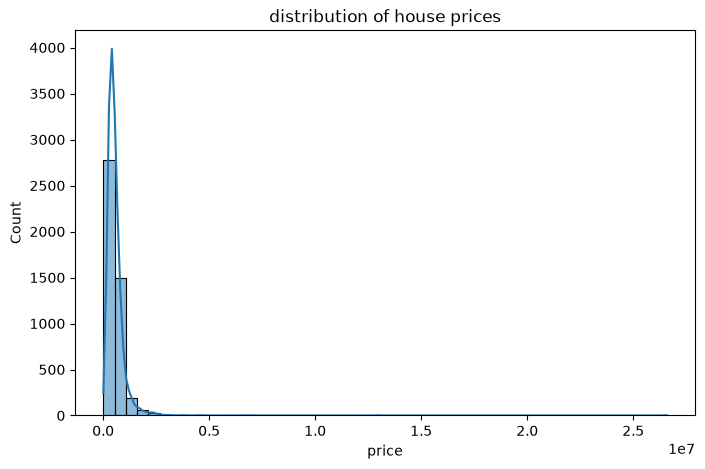

In [60]:
#HOUSE PRICE DISTRIBUTION
plt.figure(figsize=(8,5))
sns.histplot(df["price"],bins=50,kde=True)
plt.title("distribution of house prices")
plt.xlabel("price")
plt.show()

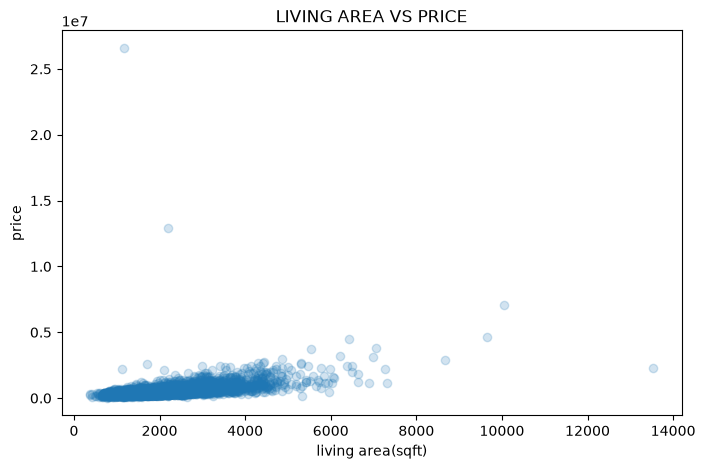

In [63]:
#LIVING AREA VS PRICE
plt.figure(figsize=(8,5))
plt.scatter(df["sqft_living"],df["price"],alpha=0.2)
plt.title("LIVING AREA VS PRICE")
plt.xlabel("living area(sqft)")
plt.ylabel("price")
plt.show()

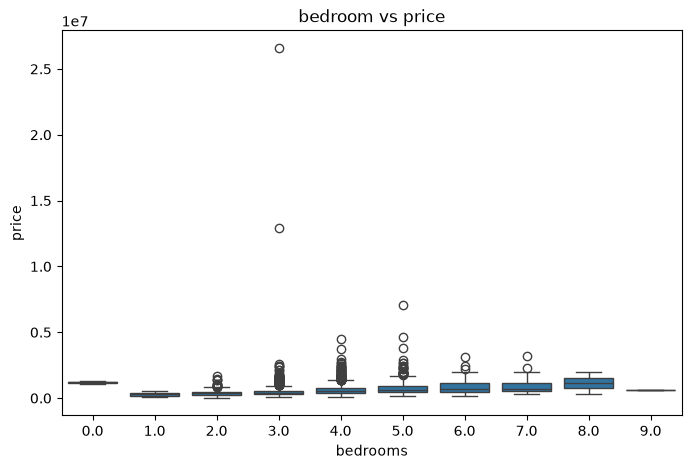

In [65]:
#BEDROOM VS PRICE
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="bedrooms",y="price")
plt.title("bedroom vs price")
plt.show()

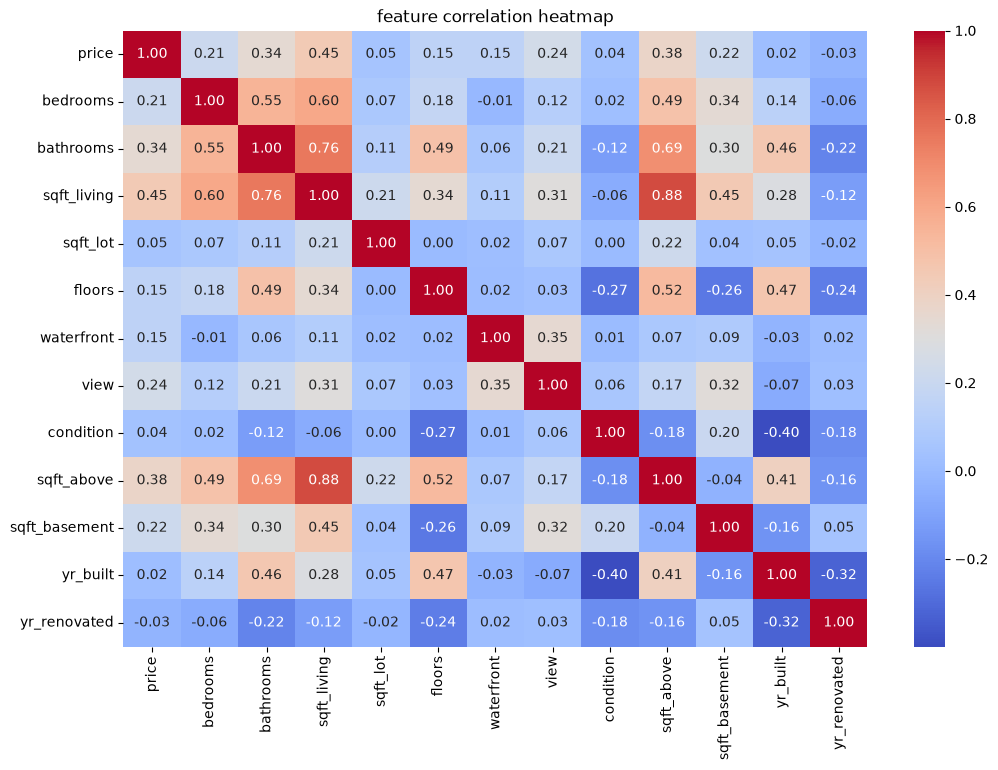

In [66]:
#correlation heatmap
plt.figure(figsize=(12,8))
numeric_df=df.select_dtypes(include="number")
sns.heatmap(numeric_df.corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("feature correlation heatmap")
plt.show()

#LINEAR REGRESSION

In [67]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score

In [ ]:
features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "sqft_above",
    "sqft_basement",
    "yr_built",
    "yr_renovated"
]
x=df[features].copy()     #x contains features used to predict the price
y=df["price"]            #y stores the value that model must learn to predict->i.e, actual house price

x=x.fillna(x.median())

#splitting data->training nd testing
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42  #0.2- 20%data for testing is reserved rest 80% for training
)

#model training
model=LinearRegression()  #LR learns relationship bw house features nd the price
model.fit(x_train,y_train)

#predict price
y_pred=model.predict(x_test)

#evaluate model
print("MAE",mean_absolute_error(y_test,y_pred)) #A lower MAE generally means more accurate predictions
print("RMSE", np.sqrt(mean_squared_error(y_test,y_pred))) #A lower RMSE is generally better.
print("R2 score",r2_score(y_test,y_pred))  #Unlike MAE, MSE, and RMSE, a higher R² is generally better



MAE 160681.99955287445
RMSE 243747.93887706607
R2 score 0.6006392304833057


visualizing actual vs predicted data


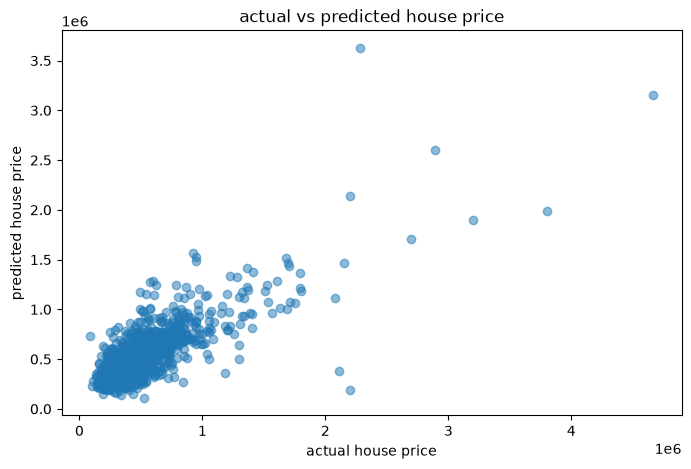

In [79]:
plt.figure(figsize=(8,5))
plt.scatter(y_test,y_pred,alpha=0.5)
plt.xlabel("actual house price")
plt.ylabel("predicted house price")
plt.title("actual vs predicted house price")
plt.show()

In [81]:
new_house = pd.DataFrame([{
    "bedrooms": 3,
    "bathrooms": 2,
    "sqft_living": 1800,
    "sqft_lot": 5000,
    "floors": 1,
    "waterfront": 0,
    "view": 0,
    "condition": 3,
    "sqft_above": 1400,
    "sqft_basement": 400,
    "yr_built": 2000,
    "yr_renovated": 0
}])
predicted_price=model.predict(new_house)[0]
print(f"predicted house price: ${predicted_price:,.2f}")

predicted house price: $357,473.29
